# Garbage Classification

## 5. Phân loại trên đặc trưng truyền thống

Notebook này huấn luyện và đánh giá các mô hình phân loại trên hai đặc trưng truyền thống của notebook 03: `hog` (8 100 chiều) và `sift_bovw` (500 chiều). Nội dung gồm baseline sàn (`DummyClassifier`), baseline chính (Logistic Regression), tuning siêu tham số cho Logistic Regression, SVM và Random Forest, phân tích lỗi, và ablation PCA.

**Quy ước đánh giá.**
- Chỉ dùng tập development (`train + val` của notebook 02, gồm 12 692 ảnh). Tập final test (3 174 ảnh) không được dùng ở đây; việc đánh giá trên final test thực hiện ở `07_final_evaluation.ipynb`.
- Đánh giá bằng 5-fold cross validation phân tầng theo lớp (`StratifiedKFold`, `seed=42`). Mọi thí nghiệm dùng cùng một cách chia fold.
- Chỉ số chính là macro-F1, báo cáo dạng `mean ± std` qua 5 fold. Chỉ số phụ gồm accuracy, macro precision, macro recall, confusion matrix và thời gian huấn luyện.
- Chuẩn hóa (`StandardScaler`) và PCA được đặt trong `Pipeline`, nên ở mỗi fold chúng chỉ được fit trên phần train của fold đó.

### 5.1. Nạp dữ liệu và thiết lập cross validation

Nạp `meta.csv` và `label2id.json` (notebook 02) cùng ba ma trận đặc trưng `hog`, `sift_bovw`, `hog_color` (notebook 03), rồi giữ lại các dòng thuộc tập development. `hog_color` chỉ dùng ở mục 5.5 để kiểm tra vai trò của màu. Kết quả của từng bước tuning được lưu vào `artifacts/results/cache/`, để các mục sau đọc lại được mà không phải chạy lại khi khởi động lại kernel.

In [1]:
# [5.1] Import module và nạp dữ liệu tập Development
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # để import được modules/ khi chạy từ thư mục notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import modules.extract as ex
import modules.evaluation as ev
import modules.classify as clf

cfg = ex.load_config()
SEED = cfg["seed"]
N_SPLITS = cfg["n_splits"]

data = clf.load_dev_data(["hog", "sift_bovw", "hog_color"], cfg)
X_dev = data["X_dev"]
y_dev = data["y_dev"]
class_names = data["class_names"]

cv = ev.get_cv(n_splits=N_SPLITS, seed=SEED)
print(f"Đã khởi tạo CV: Stratified {N_SPLITS}-Fold (seed={SEED}) | Số lớp: {len(class_names)}")

Tổng số ảnh: 15866 | Development (5-fold CV): 12692 | Final Test (niêm phong): 3174
  - hog           : shape=(12692, 8100), min=0.000, max=1.000, L2_mean=14.628
  - sift_bovw     : shape=(12692, 500), min=0.000, max=0.619, L2_mean=0.188
  - hog_color     : shape=(12692, 8228), min=0.000, max=1.000, L2_mean=1.414
Đã khởi tạo CV: Stratified 5-Fold (seed=42) | Số lớp: 12


### 5.2. Baseline

- **Baseline sàn** (`DummyClassifier`) không dùng đặc trưng ảnh. Chiến lược `most_frequent` luôn đoán lớp có nhiều ảnh nhất (`clothes`); chiến lược `stratified` đoán ngẫu nhiên theo tỷ lệ các lớp. Mô hình có học phải vượt mức này mới có ý nghĩa.
- **Baseline chính** là Logistic Regression với `C=1.0` mặc định và `class_weight="balanced"` để bù cho việc lệch lớp.

In [2]:
# [5.2] Chạy 5-fold CV cho Baseline sàn và Baseline chính (chỉ trên 2 đặc trưng chính)
X_main = {"sift_bovw": X_dev["sift_bovw"], "hog": X_dev["hog"]}
df_baselines = clf.run_baselines(X_main, y_dev, cv, seed=SEED, n_jobs=-1)
display(ev.format_results_table(df_baselines))

[Baseline sàn] Dummy (most_frequent)  | Macro-F1: 0.0416 ± 0.0000 | Acc: 0.3331
[Baseline sàn] Dummy (stratified)     | Macro-F1: 0.0793 ± 0.0038 | Acc: 0.1561
[Baseline LR ] sift_bovw      | Macro-F1: 0.4600 ± 0.0089 | Acc: 0.5635 | Fit: 2.7s/fold
[Baseline LR ] hog            | Macro-F1: 0.3234 ± 0.0083 | Acc: 0.4656 | Fit: 68.1s/fold


,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,sift_bovw,Logistic Regression,"C=1.0, class_weight=balanced",0.4600 ± 0.0089,0.5635 ± 0.0044,0.4513,0.4752,0.7102,2.75
1,hog,Logistic Regression,"C=1.0, class_weight=balanced",0.3234 ± 0.0083,0.4656 ± 0.0073,0.3230,0.3246,1.0000,68.09
2,(none),Dummy (stratified),baseline sàn,0.0793 ± 0.0038,0.1561 ± 0.0070,0.0792,0.0795,0.0814,0.03
3,(none),Dummy (most_frequent),baseline sàn,0.0416 ± 0.0000,0.3331 ± 0.0002,0.0278,0.0833,0.0416,0.03


**Kết quả.**
- `Dummy (most_frequent)` luôn đoán lớp `clothes`, đạt accuracy `0.3331` nhưng macro-F1 chỉ `0.0416`, vì 11 lớp còn lại có F1 bằng 0. `Dummy (stratified)` đạt macro-F1 `0.0793`, xấp xỉ 1/12. Đây là lý do nhóm chọn macro-F1 làm chỉ số chính: với dữ liệu lệch lớp, accuracy cao vẫn có thể ứng với một mô hình bỏ qua gần hết các lớp nhỏ.
- `LogisticRegression` mặc định (`C=1.0`) trên `sift_bovw` đạt `0.4600 ± 0.0089`, cao hơn rõ mức sàn.
- Trên `hog`, cùng cấu hình chỉ đạt `0.3234 ± 0.0083` trong khi train F1 bằng `1.0000`, tức mô hình học thuộc toàn bộ tập train. Thời gian fit `68.1 s`/fold. `C=1.0` là điều chuẩn quá yếu cho 8 100 chiều, nên phải tuning `C` trước khi so sánh các đặc trưng.

### 5.3. Tuning trên `sift_bovw` (500 chiều)

**Logistic Regression.** Với mỗi lớp $c$, mô hình tính điểm tuyến tính $z_c = w_c^\top x + b_c$, rồi đổi các điểm thành xác suất bằng softmax: $P(y=c \mid x) = e^{z_c} / \sum_j e^{z_j}$. Trọng số được học bằng cách cực tiểu cross-entropy cộng với thành phần điều chuẩn L2 $\frac{1}{2C}\lVert W \rVert^2$. `C` càng nhỏ thì trọng số lớn càng bị phạt nặng, mô hình đơn giản hơn và ít overfitting hơn.

**SVM.** Mô hình tìm siêu phẳng phân tách sao cho khoảng cách (lề) từ siêu phẳng đến các điểm gần nhất của mỗi lớp là lớn nhất. `C` cân bằng giữa lề rộng và số điểm bị phân loại sai. `LinearSVC` đặt siêu phẳng ngay trong không gian gốc. `SVC(kernel="rbf")` dùng kernel $K(x, x') = \exp(-\gamma \lVert x - x' \rVert^2)$; việc này tương đương với phân tách tuyến tính trong một không gian đặc trưng ngầm định, nên ranh giới trong không gian gốc có thể cong. Với 12 lớp, `SVC` huấn luyện một bộ phân loại cho mỗi cặp lớp (66 bộ), nên chậm hơn nhiều so với mô hình tuyến tính.

**Random Forest.** Gồm nhiều cây quyết định. Mỗi cây học trên một mẫu bootstrap của tập train, và ở mỗi nút chỉ xét một tập con ngẫu nhiên các chiều (`max_features="sqrt"`). Dự đoán cuối cùng là kết quả bỏ phiếu của các cây. Siêu tham số chính được tuning là độ sâu tối đa `max_depth`: cây càng sâu càng khớp tập train và càng dễ overfitting.

**Cách tuning.** Lưới siêu tham số đặt theo thang logarit. Một giá trị chỉ được coi là tốt nhất khi các giá trị lân cận ở cả hai phía đều cho kết quả thấp hơn. Nếu giá trị tốt nhất nằm ở biên lưới thì lưới được mở rộng thêm (mục 5.4.4).

=== Tuning Logistic Regression trên `sift_bovw` (8 cấu hình × 5 fold) ===
  [1/8] C=0.001, class_weight=balanced         -> Val F1: 0.5019 ± 0.0073 | Train F1: 0.5802 | (8.4s)
  [2/8] C=0.002, class_weight=balanced         -> Val F1: 0.5110 ± 0.0109 | Train F1: 0.6122 | (7.0s)
  [3/8] C=0.005, class_weight=balanced         -> Val F1: 0.5095 ± 0.0079 | Train F1: 0.6464 | (5.9s)
  [4/8] C=0.01, class_weight=balanced          -> Val F1: 0.5034 ± 0.0089 | Train F1: 0.6638 | (6.1s)
  [5/8] C=0.05, class_weight=balanced          -> Val F1: 0.4878 ± 0.0074 | Train F1: 0.6937 | (1.6s)
  [6/8] C=0.1, class_weight=balanced           -> Val F1: 0.4795 ± 0.0103 | Train F1: 0.6994 | (1.8s)
  [7/8] C=1.0, class_weight=balanced           -> Val F1: 0.4600 ± 0.0089 | Train F1: 0.7102 | (3.0s)
  [8/8] C=10.0, class_weight=balanced          -> Val F1: 0.4547 ± 0.0064 | Train F1: 0.7111 | (3.8s)
--> Tốt nhất: C=0.002, class_weight=balanced | Macro-F1 = 0.5110 ± 0.0109



,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,sift_bovw,Logistic Regression,"C=0.002, class_weight=balanced",0.5110 ± 0.0109,0.6079 ± 0.0042,0.5065,0.5241,0.6122,0.99
1,sift_bovw,Logistic Regression,"C=0.005, class_weight=balanced",0.5095 ± 0.0079,0.6073 ± 0.0056,0.5030,0.5230,0.6464,0.93
2,sift_bovw,Logistic Regression,"C=0.01, class_weight=balanced",0.5034 ± 0.0089,0.6016 ± 0.0059,0.4955,0.5182,0.6638,0.95
3,sift_bovw,Logistic Regression,"C=0.001, class_weight=balanced",0.5019 ± 0.0073,0.5984 ± 0.0021,0.5000,0.5147,0.5802,0.67
4,sift_bovw,Logistic Regression,"C=0.05, class_weight=balanced",0.4878 ± 0.0074,0.5896 ± 0.0060,0.4792,0.5027,0.6937,1.29
5,sift_bovw,Logistic Regression,"C=0.1, class_weight=balanced",0.4795 ± 0.0103,0.5823 ± 0.0070,0.4710,0.4942,0.6994,1.54
6,sift_bovw,Logistic Regression,"C=1.0, class_weight=balanced",0.4600 ± 0.0089,0.5635 ± 0.0044,0.4513,0.4752,0.7102,2.64
7,sift_bovw,Logistic Regression,"C=10.0, class_weight=balanced",0.4547 ± 0.0064,0.5585 ± 0.0028,0.4460,0.4701,0.7111,3.45


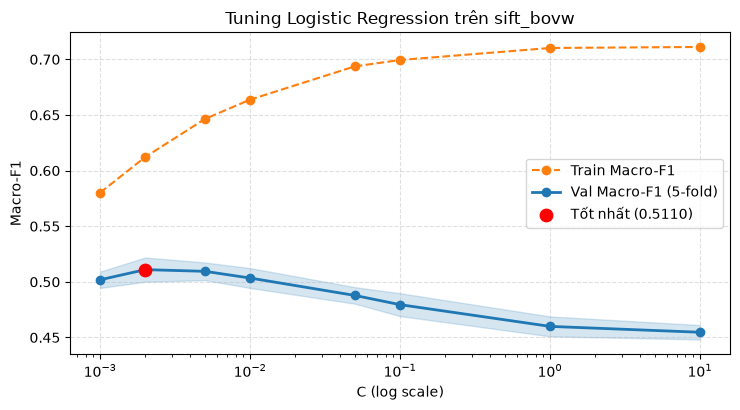

In [4]:
# [5.3.1] Tuning Logistic Regression trên sift_bovw
sift_lr_grid = [
    {"C": c, "class_weight": "balanced"}
    for c in [0.001, 0.002, 0.005, 0.01, 0.05, 0.1, 1.0, 10.0]
]
df_sift_lr, best_sift_lr = clf.tune_model("sift_bovw", X_dev["sift_bovw"], y_dev, cv, "lr", sift_lr_grid, seed=SEED)
display(ev.format_results_table(df_sift_lr))

fig = ev.plot_tuning_curve(df_sift_lr, "param_C", "Tuning Logistic Regression trên sift_bovw", x_label="C (log scale)", log_x=True)
plt.show()

=== Tuning SVM (Linear) trên `sift_bovw` (4 cấu hình × 5 fold) ===
  [1/4] C=0.005, class_weight=balanced         -> Val F1: 0.5028 ± 0.0132 | Train F1: 0.6537 | (18.0s)
  [2/4] C=0.01, class_weight=balanced          -> Val F1: 0.5014 ± 0.0131 | Train F1: 0.6624 | (19.1s)
  [3/4] C=0.1, class_weight=balanced           -> Val F1: 0.4962 ± 0.0135 | Train F1: 0.6718 | (27.4s)
  [4/4] C=1.0, class_weight=balanced           -> Val F1: 0.4942 ± 0.0120 | Train F1: 0.6738 | (41.3s)
--> Tốt nhất: C=0.005, class_weight=balanced | Macro-F1 = 0.5028 ± 0.0132

=== Tuning SVM (RBF) trên `sift_bovw` (4 cấu hình × 5 fold) ===
  [1/4] C=0.5, gamma=scale, class_weight=balanced -> Val F1: 0.5404 ± 0.0050 | Train F1: 0.7847 | (108.1s)
  [2/4] C=1.0, gamma=scale, class_weight=balanced -> Val F1: 0.5680 ± 0.0042 | Train F1: 0.8957 | (149.6s)
  [3/4] C=5.0, gamma=scale, class_weight=balanced -> Val F1: 0.5712 ± 0.0043 | Train F1: 0.9844 | (437.4s)
  [4/4] C=10.0, gamma=scale, class_weight=balanced -> Val F1:

,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,sift_bovw,SVM (RBF),"C=10.0, gamma=scale, class_weight=balanced",0.5718 ± 0.0041,0.6791 ± 0.0037,0.5920,0.5599,0.9939,208.33
1,sift_bovw,SVM (RBF),"C=5.0, gamma=scale, class_weight=balanced",0.5712 ± 0.0043,0.6766 ± 0.0042,0.5879,0.5630,0.9844,151.78
2,sift_bovw,SVM (RBF),"C=1.0, gamma=scale, class_weight=balanced",0.5680 ± 0.0042,0.6617 ± 0.0052,0.5752,0.5699,0.8957,48.68
3,sift_bovw,SVM (RBF),"C=0.5, gamma=scale, class_weight=balanced",0.5404 ± 0.0050,0.6352 ± 0.0040,0.5457,0.5456,0.7847,55.40
4,sift_bovw,SVM (Linear),"C=0.005, class_weight=balanced",0.5028 ± 0.0132,0.6181 ± 0.0087,0.5017,0.5076,0.6537,17.49
5,sift_bovw,SVM (Linear),"C=0.01, class_weight=balanced",0.5014 ± 0.0131,0.6162 ± 0.0085,0.4993,0.5072,0.6624,18.64
6,sift_bovw,SVM (Linear),"C=0.1, class_weight=balanced",0.4962 ± 0.0135,0.6111 ± 0.0095,0.4929,0.5033,0.6718,26.92
7,sift_bovw,SVM (Linear),"C=1.0, class_weight=balanced",0.4942 ± 0.0120,0.6092 ± 0.0083,0.4908,0.5012,0.6738,39.78


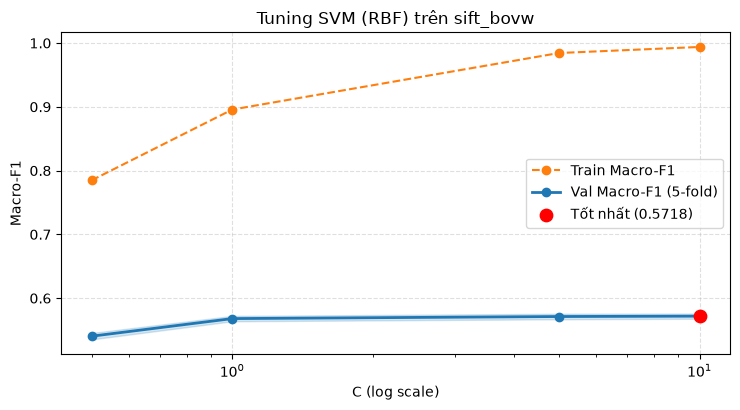

In [5]:
# [5.3.2] Tuning SVM (LinearSVC và SVC kernel RBF) trên sift_bovw
sift_lsvm_grid = [{"C": c, "class_weight": "balanced"} for c in [0.005, 0.01, 0.1, 1.0]]
df_sift_lsvm, best_sift_lsvm = clf.tune_model("sift_bovw", X_dev["sift_bovw"], y_dev, cv, "linear_svm", sift_lsvm_grid, seed=SEED)

sift_rbf_grid = [{"C": c, "gamma": "scale", "class_weight": "balanced"} for c in [0.5, 1.0, 5.0, 10.0]]
df_sift_rbf, best_sift_rbf = clf.tune_model("sift_bovw", X_dev["sift_bovw"], y_dev, cv, "rbf_svm", sift_rbf_grid, seed=SEED)

df_sift_svm = pd.concat([df_sift_lsvm, df_sift_rbf], ignore_index=True)
display(ev.format_results_table(df_sift_svm))

fig = ev.plot_tuning_curve(df_sift_rbf, "param_C", "Tuning SVM (RBF) trên sift_bovw", x_label="C (log scale)", log_x=True)
plt.show()

In [6]:
# [5.3.3] Tuning Random Forest trên sift_bovw
sift_rf_grid = [
    {"n_estimators": 200, "max_depth": 10, "max_features": "sqrt", "class_weight": "balanced_subsample"},
    {"n_estimators": 200, "max_depth": 12, "max_features": "sqrt", "class_weight": "balanced_subsample"},
    {"n_estimators": 200, "max_depth": 15, "max_features": "sqrt", "class_weight": "balanced_subsample"},
    {"n_estimators": 200, "max_depth": 25, "max_features": "sqrt", "class_weight": "balanced_subsample"},
    {"n_estimators": 200, "max_depth": None, "max_features": "sqrt", "class_weight": "balanced_subsample"},
    {"n_estimators": 300, "max_depth": None, "max_features": "sqrt", "class_weight": "balanced_subsample"},
    {"n_estimators": 300, "max_depth": None, "max_features": "log2", "class_weight": "balanced_subsample"},
]
df_sift_rf, best_sift_rf = clf.tune_model("sift_bovw", X_dev["sift_bovw"], y_dev, cv, "rf", sift_rf_grid, scale=False, seed=SEED)
display(ev.format_results_table(df_sift_rf))

=== Tuning Random Forest trên `sift_bovw` (7 cấu hình × 5 fold) ===
  [1/7] n_estimators=200, max_depth=10, max_features=sqrt, class_weight=balanced_subsample -> Val F1: 0.4550 ± 0.0139 | Train F1: 0.7839 | (4.6s)
  [2/7] n_estimators=200, max_depth=12, max_features=sqrt, class_weight=balanced_subsample -> Val F1: 0.4782 ± 0.0141 | Train F1: 0.8854 | (4.8s)
  [3/7] n_estimators=200, max_depth=15, max_features=sqrt, class_weight=balanced_subsample -> Val F1: 0.4899 ± 0.0142 | Train F1: 0.9636 | (5.1s)
  [4/7] n_estimators=200, max_depth=25, max_features=sqrt, class_weight=balanced_subsample -> Val F1: 0.4897 ± 0.0128 | Train F1: 0.9998 | (28.4s)
  [5/7] n_estimators=200, max_depth=None, max_features=sqrt, class_weight=balanced_subsample -> Val F1: 0.4808 ± 0.0189 | Train F1: 1.0000 | (42.0s)
  [6/7] n_estimators=300, max_depth=None, max_features=sqrt, class_weight=balanced_subsample -> Val F1: 0.4788 ± 0.0169 | Train F1: 1.0000 | (63.8s)
  [7/7] n_estimators=300, max_depth=None, max_fea

,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,sift_bovw,Random Forest,"n_estimators=200, max_depth=15, max_features=s...",0.4899 ± 0.0142,0.5947 ± 0.0102,0.5401,0.4707,0.9636,0.84
1,sift_bovw,Random Forest,"n_estimators=200, max_depth=25, max_features=s...",0.4897 ± 0.0128,0.6064 ± 0.0061,0.5971,0.4450,0.9998,4.94
2,sift_bovw,Random Forest,"n_estimators=200, max_depth=None, max_features...",0.4808 ± 0.0189,0.5971 ± 0.0091,0.6307,0.4251,1.0000,7.53
3,sift_bovw,Random Forest,"n_estimators=300, max_depth=None, max_features...",0.4788 ± 0.0169,0.5957 ± 0.0079,0.6282,0.4234,1.0000,11.56
4,sift_bovw,Random Forest,"n_estimators=200, max_depth=12, max_features=s...",0.4782 ± 0.0141,0.5730 ± 0.0107,0.5146,0.4688,0.8854,0.80
5,sift_bovw,Random Forest,"n_estimators=300, max_depth=None, max_features...",0.4622 ± 0.0151,0.5824 ± 0.0072,0.6444,0.4029,1.0000,2.89
6,sift_bovw,Random Forest,"n_estimators=200, max_depth=10, max_features=s...",0.4550 ± 0.0139,0.5472 ± 0.0087,0.4848,0.4517,0.7839,0.76


**Kết quả trên `sift_bovw`.**
- **Logistic Regression.** Giảm `C` từ `10` xuống `0.002` làm khoảng cách train–val thu hẹp (train F1 `0.7111` → `0.6122`) và val F1 tăng từ `0.4547` lên `0.5110 ± 0.0109`. Giảm tiếp xuống `C=0.001` thì val F1 giảm còn `0.5019`. Đỉnh tại `C=0.002` có hai phía đều thấp hơn.
- **SVM.** `LinearSVC` tốt nhất đạt `0.5028 ± 0.0132` (`C=0.005`), tương đương Logistic Regression vì cả hai đều là mô hình tuyến tính. `SVC(kernel="rbf")` đạt `0.5718 ± 0.0041` tại `C=10`, cao hơn Logistic Regression khoảng 0.06. Mức chênh này lớn hơn nhiều so với độ lệch chuẩn giữa các fold, cho thấy ranh giới giữa các lớp trên histogram BoVW không tuyến tính. Từ `C=5` trở lên val F1 gần như không đổi (`0.5712`, `0.5718`, và `0.5718`, `0.5708` ở `C=20`, `C=50` trong mục 5.4.4) trong khi train F1 tiến tới 1, nên `C=10` được giữ.
- **Random Forest.** Cây không giới hạn độ sâu đạt train F1 `1.0000` nhưng val F1 chỉ `0.4808`. Giới hạn `max_depth=15` cho kết quả tốt nhất `0.4899 ± 0.0142`; giảm xuống `12` và `10` thì val F1 giảm (`0.4782`, `0.4550`).

**Kết luận.** Trên `sift_bovw`, SVM RBF tốt nhất. Logistic Regression và Linear SVM gần nhau; Random Forest thấp nhất và có độ lệch chuẩn lớn nhất (`0.0142`).

### 5.4. Huấn luyện & Tuning 3 mô hình trên `hog` (8 100 chiều)

`hog` có 8 100 chiều, gần bằng số ảnh train mỗi fold (~10 150), nên mô hình rất dễ học thuộc tập train nếu điều chuẩn yếu. Số chiều lớn cũng làm thời gian huấn luyện tăng mạnh. Mục này gồm:
- **5.4.1 – 5.4.3:** chạy lưới ban đầu cho Logistic Regression, Linear SVM và Random Forest trên 8 100 chiều gốc.
- **5.4.4:** mở rộng lưới ở những mô hình có điểm tốt nhất nằm sát biên lưới ban đầu.

**Về Linear SVM.** Trên `sift_bovw` dùng `LinearSVC` (solver liblinear). Trên `hog`, `LinearSVC` mất hơn 100 giây cho mỗi lần fit một cấu hình trên một fold, nên được thay bằng `SGDClassifier(loss="hinge", penalty="l2")`. Đây vẫn là SVM tuyến tính (hàm mất mát hinge, điều chuẩn L2) nhưng được giải xấp xỉ bằng gradient ngẫu nhiên; siêu tham số `alpha` tỷ lệ nghịch với `C` (`alpha` lớn tương ứng điều chuẩn mạnh). Khi đọc kết quả cần lưu ý hai đặc trưng dùng hai bộ giải khác nhau cho cùng họ mô hình.

**SVM kernel RBF** trên 8 100 chiều gốc quá chậm nên chỉ được chạy sau khi giảm chiều bằng PCA ở mục 5.6.

=== Tuning Logistic Regression trên `hog` (6 cấu hình × 5 fold) ===
  [1/6] C=0.0005, class_weight=balanced        -> Val F1: 0.3831 ± 0.0087 | Train F1: 0.8304 | (159.6s)
  [2/6] C=0.001, class_weight=balanced         -> Val F1: 0.3708 ± 0.0089 | Train F1: 0.9057 | (138.0s)
  [3/6] C=0.005, class_weight=balanced         -> Val F1: 0.3504 ± 0.0120 | Train F1: 0.9806 | (241.4s)
  [4/6] C=0.01, class_weight=balanced          -> Val F1: 0.3459 ± 0.0133 | Train F1: 0.9912 | (224.1s)
  [5/6] C=0.1, class_weight=balanced           -> Val F1: 0.3347 ± 0.0105 | Train F1: 1.0000 | (205.1s)
  [6/6] C=1.0, class_weight=balanced           -> Val F1: 0.3234 ± 0.0083 | Train F1: 1.0000 | (72.7s)
--> Tốt nhất: C=0.0005, class_weight=balanced | Macro-F1 = 0.3831 ± 0.0087



,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,hog,Logistic Regression,"C=0.0005, class_weight=balanced",0.3831 ± 0.0087,0.5110 ± 0.0067,0.3814,0.3896,0.8304,145.71
1,hog,Logistic Regression,"C=0.001, class_weight=balanced",0.3708 ± 0.0089,0.5021 ± 0.0075,0.3687,0.3762,0.9057,108.05
2,hog,Logistic Regression,"C=0.005, class_weight=balanced",0.3504 ± 0.0120,0.4875 ± 0.0099,0.3499,0.3527,0.9806,214.87
3,hog,Logistic Regression,"C=0.01, class_weight=balanced",0.3459 ± 0.0133,0.4836 ± 0.0107,0.3463,0.3471,0.9912,214.88
4,hog,Logistic Regression,"C=0.1, class_weight=balanced",0.3347 ± 0.0105,0.4746 ± 0.0077,0.3362,0.3347,1.0000,176.98
5,hog,Logistic Regression,"C=1.0, class_weight=balanced",0.3234 ± 0.0083,0.4656 ± 0.0073,0.3230,0.3246,1.0000,66.04


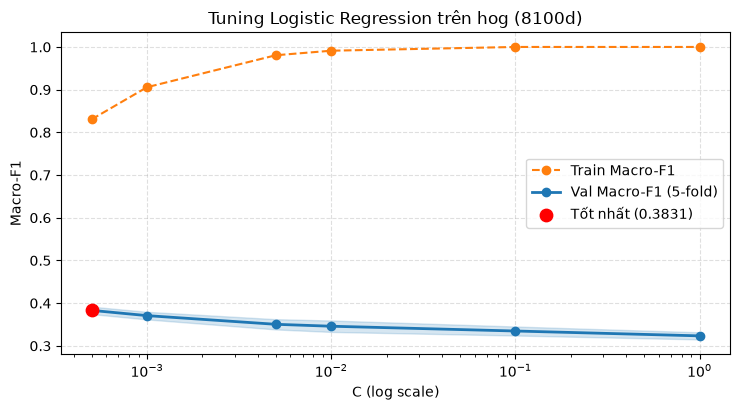

In [3]:
# [5.4.1] Tuning Logistic Regression trên hog (8100 chiều)
hog_lr_grid = [
    {"C": c, "class_weight": "balanced"}
    for c in [0.0005, 0.001, 0.005, 0.01, 0.1, 1.0]
]
df_hog_lr, best_hog_lr = clf.tune_model("hog", X_dev["hog"], y_dev, cv, "lr", hog_lr_grid, seed=SEED)
display(ev.format_results_table(df_hog_lr))

fig = ev.plot_tuning_curve(df_hog_lr, "param_C", "Tuning Logistic Regression trên hog (8100d)", x_label="C (log scale)", log_x=True)
plt.show()

=== Tuning SVM (Linear-SGD) trên `hog` (5 cấu hình × 5 fold) ===
  [1/5] alpha=0.01, class_weight=balanced      -> Val F1: 0.3610 ± 0.0085 | Train F1: 0.7275 | (660.8s)
  [2/5] alpha=0.05, class_weight=balanced      -> Val F1: 0.3669 ± 0.0110 | Train F1: 0.6835 | (187.6s)
  [3/5] alpha=0.1, class_weight=balanced       -> Val F1: 0.3735 ± 0.0114 | Train F1: 0.6707 | (134.7s)
  [4/5] alpha=0.5, class_weight=balanced       -> Val F1: 0.3855 ± 0.0139 | Train F1: 0.6411 | (70.7s)
  [5/5] alpha=1.0, class_weight=balanced       -> Val F1: 0.3877 ± 0.0084 | Train F1: 0.6227 | (75.9s)
--> Tốt nhất: alpha=1.0, class_weight=balanced | Macro-F1 = 0.3877 ± 0.0084



,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,hog,SVM (Linear-SGD),"alpha=1.0, class_weight=balanced",0.3877 ± 0.0084,0.5351 ± 0.0093,0.4009,0.3862,0.6227,14.58
1,hog,SVM (Linear-SGD),"alpha=0.5, class_weight=balanced",0.3855 ± 0.0139,0.5328 ± 0.0121,0.3976,0.3837,0.6411,13.91
2,hog,SVM (Linear-SGD),"alpha=0.1, class_weight=balanced",0.3735 ± 0.0114,0.5244 ± 0.0095,0.3822,0.3710,0.6707,26.70
3,hog,SVM (Linear-SGD),"alpha=0.05, class_weight=balanced",0.3669 ± 0.0110,0.5207 ± 0.0093,0.3749,0.3645,0.6835,37.27
4,hog,SVM (Linear-SGD),"alpha=0.01, class_weight=balanced",0.3610 ± 0.0085,0.5158 ± 0.0068,0.3681,0.3582,0.7275,131.67


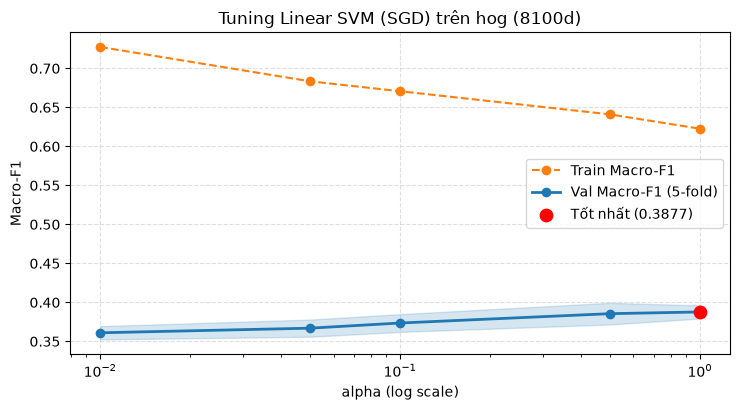

In [3]:
# [5.4.2] Tuning Linear SVM (SGDClassifier loss='hinge') trên hog (8100 chiều)
hog_svm_grid = [
    {"alpha": a, "class_weight": "balanced"}
    for a in [0.01, 0.05, 0.1, 0.5, 1.0]
]
df_hog_svm, best_hog_svm = clf.tune_model("hog", X_dev["hog"], y_dev, cv, "sgd_svm", hog_svm_grid, seed=SEED)
display(ev.format_results_table(df_hog_svm))

fig = ev.plot_tuning_curve(df_hog_svm, "param_alpha", "Tuning Linear SVM (SGD) trên hog (8100d)", x_label="alpha (log scale)", log_x=True)
plt.show()

In [4]:
# [5.4.3] Tuning Random Forest trên hog (8100 chiều)
hog_rf_grid = [
    {"n_estimators": 200, "max_depth": 15, "max_features": "sqrt", "class_weight": "balanced_subsample"},
    {"n_estimators": 200, "max_depth": 25, "max_features": "sqrt", "class_weight": "balanced_subsample"},
    {"n_estimators": 200, "max_depth": None, "max_features": "sqrt", "class_weight": "balanced_subsample"},
    {"n_estimators": 300, "max_depth": None, "max_features": "sqrt", "class_weight": "balanced_subsample"},
]
df_hog_rf, best_hog_rf = clf.tune_model("hog", X_dev["hog"], y_dev, cv, "rf", hog_rf_grid, scale=False, seed=SEED)
display(ev.format_results_table(df_hog_rf))

=== Tuning Random Forest trên `hog` (4 cấu hình × 5 fold) ===
  [1/4] n_estimators=200, max_depth=15, max_features=sqrt, class_weight=balanced_subsample -> Val F1: 0.3484 ± 0.0094 | Train F1: 0.9999 | (279.5s)
  [2/4] n_estimators=200, max_depth=25, max_features=sqrt, class_weight=balanced_subsample -> Val F1: 0.2967 ± 0.0082 | Train F1: 1.0000 | (437.5s)
  [3/4] n_estimators=200, max_depth=None, max_features=sqrt, class_weight=balanced_subsample -> Val F1: 0.3009 ± 0.0113 | Train F1: 1.0000 | (109.5s)
  [4/4] n_estimators=300, max_depth=None, max_features=sqrt, class_weight=balanced_subsample -> Val F1: 0.3043 ± 0.0130 | Train F1: 1.0000 | (98.7s)
--> Tốt nhất: n_estimators=200, max_depth=15, max_features=sqrt, class_weight=balanced_subsample | Macro-F1 = 0.3484 ± 0.0094



,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,hog,Random Forest,"n_estimators=200, max_depth=15, max_features=s...",0.3484 ± 0.0094,0.5128 ± 0.0051,0.4926,0.3174,0.9999,54.56
1,hog,Random Forest,"n_estimators=300, max_depth=None, max_features...",0.3043 ± 0.0130,0.4864 ± 0.0066,0.5727,0.2791,1.0000,19.25
2,hog,Random Forest,"n_estimators=200, max_depth=None, max_features...",0.3009 ± 0.0113,0.4845 ± 0.0056,0.5439,0.2763,1.0000,21.55
3,hog,Random Forest,"n_estimators=200, max_depth=25, max_features=s...",0.2967 ± 0.0082,0.4841 ± 0.0038,0.5489,0.2738,1.0000,86.37


**Nhận xét lưới ban đầu.**
- Cả ba mô hình đều cho thấy overfitting rõ khi điều chuẩn yếu. Logistic Regression với `C ≥ 0.01` có train F1 trên `0.99` nhưng val F1 chỉ `0.33–0.35`. Random Forest với `max_depth=25` hoặc không giới hạn có train F1 `1.0000` và val F1 khoảng `0.30`, trong khi `max_depth=15` đạt `0.3484`.
- Điểm tốt nhất của cả ba mô hình đều nằm ở **biên lưới**: Logistic Regression ở giá trị `C` nhỏ nhất đã thử (`0.0005`), SGD ở `alpha` lớn nhất (`1.0`, vẫn đang tăng so với `0.5`), Random Forest ở `max_depth` nhỏ nhất (`15`). Khi đỉnh nằm ở biên thì chưa biết điểm thử tiếp theo có tốt hơn không.

Vì vậy mục 5.4.4 mở rộng lưới về phía điều chuẩn mạnh hơn: `C < 0.0005`, `alpha > 1`, `max_depth < 15`. Việc mở rộng dừng khi val F1 giảm so với điểm tốt nhất, tức đã có điểm thấp hơn ở cả hai phía. Mục này cũng thử thêm `C=20` và `C=50` cho SVM RBF trên `sift_bovw`, vì `C=10` cũng là giá trị lớn nhất của lưới ban đầu.

=== Mở rộng biên Logistic Regression trên `hog` (đỉnh hiện tại: 0.3831) ===
  [+1] C=0.0002, class_weight=balanced        -> Val F1: 0.3937 ± 0.0095 | Train F1: 0.7047 | (248.3s)
  [+2] C=0.0001, class_weight=balanced        -> Val F1: 0.3953 ± 0.0094 | Train F1: 0.6172 | (467.6s)
  [+3] C=5e-05, class_weight=balanced         -> Val F1: 0.3880 ± 0.0091 | Train F1: 0.5444 | (314.9s)
  --> Điểm đã đi xuống (0.3880 < 0.3953), đã bắt trọn đỉnh. Dừng mở rộng!
--> Đỉnh cuối cùng: C=0.0001, class_weight=balanced | Macro-F1 = 0.3953 ± 0.0094

=== Mở rộng biên SVM (Linear-SGD) trên `hog` (đỉnh hiện tại: 0.3877) ===
  [+1] alpha=2.0, class_weight=balanced       -> Val F1: 0.3861 ± 0.0114 | Train F1: 0.6056 | (208.0s)
  [+2] alpha=5.0, class_weight=balanced       -> Val F1: 0.3272 ± 0.0240 | Train F1: 0.5511 | (337.6s)
  --> Điểm đã đi xuống (0.3272 < 0.3877), đã bắt trọn đỉnh. Dừng mở rộng!
--> Đỉnh cuối cùng: alpha=1.0, class_weight=balanced | Macro-F1 = 0.3877 ± 0.0084

=== Mở rộng biên Random

,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,hog,Logistic Regression,"C=0.0001, class_weight=balanced",0.3953 ± 0.0094,0.5176 ± 0.0081,0.3964,0.4047,0.6172,92.32
1,hog,Logistic Regression,"C=0.0002, class_weight=balanced",0.3937 ± 0.0095,0.5180 ± 0.0081,0.3927,0.4024,0.7047,48.77
2,hog,Logistic Regression,"C=5e-05, class_weight=balanced",0.3880 ± 0.0091,0.5108 ± 0.0078,0.3919,0.3970,0.5444,61.85
3,hog,SVM (Linear-SGD),"alpha=1.0, class_weight=balanced",0.3877 ± 0.0084,0.5351 ± 0.0093,0.4009,0.3862,0.6227,14.58
4,hog,SVM (Linear-SGD),"alpha=2.0, class_weight=balanced",0.3861 ± 0.0114,0.5322 ± 0.0091,0.4055,0.3805,0.6056,40.13
5,hog,SVM (Linear-SGD),"alpha=0.5, class_weight=balanced",0.3855 ± 0.0139,0.5328 ± 0.0121,0.3976,0.3837,0.6411,13.91
6,hog,Logistic Regression,"C=0.0005, class_weight=balanced",0.3831 ± 0.0087,0.5110 ± 0.0067,0.3814,0.3896,0.8304,145.71
7,hog,Random Forest,"n_estimators=200, max_depth=10, max_features=s...",0.3768 ± 0.0102,0.5190 ± 0.0087,0.4308,0.3756,0.9239,65.41
8,hog,Random Forest,"n_estimators=200, max_depth=12, max_features=s...",0.3760 ± 0.0124,0.5266 ± 0.0068,0.4523,0.3607,0.9838,65.82
9,hog,SVM (Linear-SGD),"alpha=0.1, class_weight=balanced",0.3735 ± 0.0114,0.5244 ± 0.0095,0.3822,0.3710,0.6707,26.70


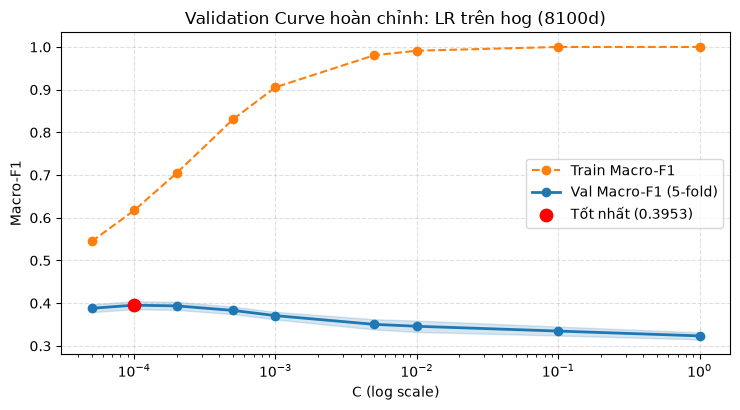

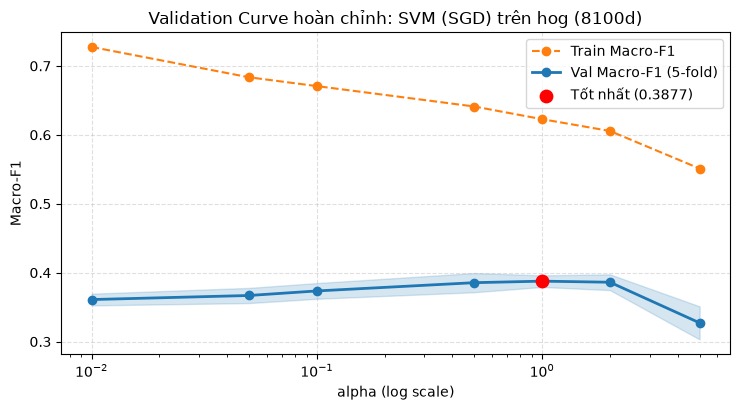

=== Mở rộng biên SVM (RBF) trên `sift_bovw` (đỉnh hiện tại: 0.5718) ===
  [+1] C=20.0, gamma=scale, class_weight=balanced -> Val F1: 0.5718 ± 0.0055 | Train F1: 0.9977 | (248.6s)
  [+2] C=50.0, gamma=scale, class_weight=balanced -> Val F1: 0.5708 ± 0.0049 | Train F1: 0.9996 | (460.3s)
  --> Điểm đã đi xuống (0.5708 < 0.5718), đã bắt trọn đỉnh. Dừng mở rộng!
--> Đỉnh cuối cùng: C=10.0, gamma=scale, class_weight=balanced | Macro-F1 = 0.5718 ± 0.0041



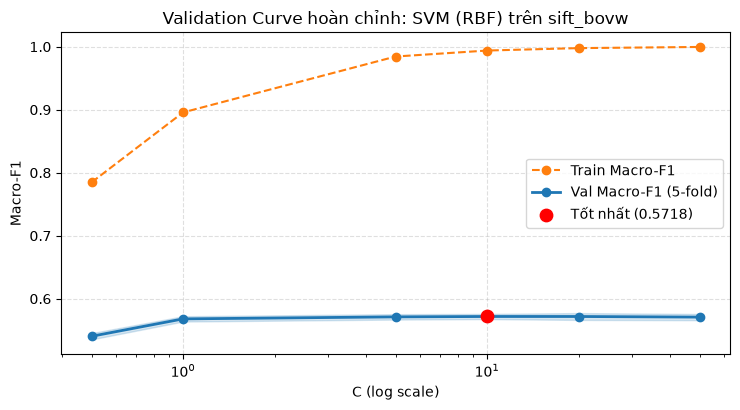

In [2]:
# [5.4.4] Mở rộng biên tự động (Coarse-to-Fine) cho `hog` để bắt trọn đỉnh tối ưu
# Nạp lại kết quả đã chạy ở 5.4.1 - 5.4.3 từ cache (không phải chạy lại từ đầu)
df_hog_lr = clf.load_cache("hog_lr", cfg)
df_hog_svm = clf.load_cache("hog_svm", cfg)
df_hog_rf = clf.load_cache("hog_rf", cfg)

# 1. Mở rộng biên LR về phía C nhỏ hơn (0.0002 -> 0.0001 -> 0.00005)
df_hog_lr, best_hog_lr = clf.expand_tuning_edge(
    df_hog_lr, "hog", X_dev["hog"], y_dev, cv, "lr",
    candidate_params=[{"C": c, "class_weight": "balanced"} for c in [0.0002, 0.0001, 0.00005]],
    sort_col="param_C", seed=SEED,
)
clf.save_cache(df_hog_lr, "hog_lr", cfg)

# 2. Mở rộng biên SVM (Linear-SGD) về phía alpha lớn hơn (2.0 -> 5.0 -> 10.0)
df_hog_svm, best_hog_svm = clf.expand_tuning_edge(
    df_hog_svm, "hog", X_dev["hog"], y_dev, cv, "sgd_svm",
    candidate_params=[{"alpha": a, "class_weight": "balanced"} for a in [2.0, 5.0, 10.0]],
    sort_col="param_alpha", seed=SEED,
)
clf.save_cache(df_hog_svm, "hog_svm", cfg)

# 3. Mở rộng biên Random Forest về phía cây nông hơn (max_depth = 12 -> 10 -> 8)
df_hog_rf, best_hog_rf = clf.expand_tuning_edge(
    df_hog_rf, "hog", X_dev["hog"], y_dev, cv, "rf",
    candidate_params=[
        {"n_estimators": 200, "max_depth": d, "max_features": "sqrt", "class_weight": "balanced_subsample"}
        for d in [12, 10, 8]
    ],
    scale=False, seed=SEED,
)
clf.save_cache(df_hog_rf, "hog_rf", cfg)

display(ev.format_results_table(pd.concat([df_hog_lr, df_hog_svm, df_hog_rf], ignore_index=True)).head(10))

fig = ev.plot_tuning_curve(df_hog_lr, "param_C", "Validation Curve hoàn chỉnh: LR trên hog (8100d)", x_label="C (log scale)", log_x=True)
plt.show()
fig = ev.plot_tuning_curve(df_hog_svm, "param_alpha", "Validation Curve hoàn chỉnh: SVM (SGD) trên hog (8100d)", x_label="alpha (log scale)", log_x=True)
plt.show()

# 4. Kiểm chứng mốc biên C=20.0 (và 50.0 nếu còn tăng) cho SVM (RBF) trên sift_bovw
df_sift_svm = clf.load_cache("sift_svm", cfg)
df_sift_lsvm = df_sift_svm[df_sift_svm["model_type"] == "linear_svm"].copy()
df_sift_rbf_only = df_sift_svm[df_sift_svm["model_type"] == "rbf_svm"].copy()

df_sift_rbf_only, best_sift_rbf = clf.expand_tuning_edge(
    df_sift_rbf_only, "sift_bovw", X_dev["sift_bovw"], y_dev, cv, "rbf_svm",
    candidate_params=[{"C": c, "gamma": "scale", "class_weight": "balanced"} for c in [20.0, 50.0]],
    sort_col="param_C", seed=SEED, tol_drop=0.0005,
)
df_sift_svm = pd.concat([df_sift_lsvm, df_sift_rbf_only], ignore_index=True)
clf.save_cache(df_sift_svm, "sift_svm", cfg)

fig = ev.plot_tuning_curve(df_sift_rbf_only, "param_C", "Validation Curve hoàn chỉnh: SVM (RBF) trên sift_bovw", x_label="C (log scale)", log_x=True)
plt.show()

**Kết quả mở rộng lưới.**

| Mô hình trên `hog` | Tốt nhất lưới ban đầu | Sau khi mở rộng | Điểm kế tiếp (giảm) |
|---|---|---|---|
| Logistic Regression | `C=0.0005`: `0.3831` | `C=0.0001`: **`0.3953 ± 0.0094`** | `C=5e-5`: `0.3880` |
| Linear SVM (SGD) | `alpha=1`: `0.3877` | không đổi: **`0.3877 ± 0.0084`** | `alpha=2`: `0.3861`, `alpha=5`: `0.3272` |
| Random Forest | `max_depth=15`: `0.3484` | `max_depth=10`: **`0.3768 ± 0.0102`** | `max_depth=8`: `0.3523` |

- Logistic Regression và Random Forest đều tăng thêm sau khi mở rộng, nên lưới ban đầu chưa đủ. Linear SVM (SGD) đã ở đúng đỉnh.
- Trên `hog`, ba mô hình chênh nhau dưới 0.02, xấp xỉ hai lần độ lệch chuẩn giữa các fold, nên không mô hình nào vượt trội rõ rệt.
- Với SVM RBF trên `sift_bovw`, `C=20` cho cùng kết quả `0.5718` và `C=50` giảm còn `0.5708`, nên giữ `C=10`.

**Kết luận.** Sau tuning, `hog` gốc đạt tối đa `0.3953`, thấp hơn `sift_bovw` (`0.5718`) khoảng 0.18. Mục 5.5 xem các lỗi tập trung ở lớp nào, mục 5.6 kiểm tra xem giảm chiều có giúp `hog` hay không.

### 5.5. So sánh 6 tổ hợp và phân tích lỗi

Với mỗi đặc trưng và mỗi họ mô hình (LR, SVM, RF), lấy cấu hình có macro-F1 cao nhất, được 6 tổ hợp. Với mô hình tốt nhất trên mỗi đặc trưng, lấy dự đoán out-of-fold (mỗi ảnh được dự đoán bởi mô hình không thấy ảnh đó lúc huấn luyện) để vẽ confusion matrix chuẩn hóa theo hàng và F1 của từng lớp. Cuối cùng, so sánh `hog` với `hog_color` trên cùng một mô hình để kiểm tra ảnh hưởng của màu.

=== Bảng tổng hợp 6 tổ hợp tốt nhất (nhánh Truyền thống) ===


,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,sift_bovw,SVM (RBF),"C=10.0, gamma=scale, class_weight=balanced",0.5718 ± 0.0041,0.6791 ± 0.0037,0.5920,0.5599,0.9939,208.33
1,sift_bovw,Logistic Regression,"C=0.002, class_weight=balanced",0.5110 ± 0.0109,0.6079 ± 0.0042,0.5065,0.5241,0.6122,0.99
2,sift_bovw,Random Forest,"n_estimators=200, max_depth=15, max_features=s...",0.4899 ± 0.0142,0.5947 ± 0.0102,0.5401,0.4707,0.9636,0.84
3,hog,Logistic Regression,"C=0.0001, class_weight=balanced",0.3953 ± 0.0094,0.5176 ± 0.0081,0.3964,0.4047,0.6172,92.32
4,hog,SVM (Linear-SGD),"alpha=1.0, class_weight=balanced",0.3877 ± 0.0084,0.5351 ± 0.0093,0.4009,0.3862,0.6227,14.58
5,hog,Random Forest,"n_estimators=200, max_depth=10, max_features=s...",0.3768 ± 0.0102,0.5190 ± 0.0087,0.4308,0.3756,0.9239,65.41


Đã lưu biểu đồ: d:\A_Learning\HK1_2026-2027\Program for AI and Data - CO3135\GarbageClassification\artifacts/figures\trad_model_comparison.png


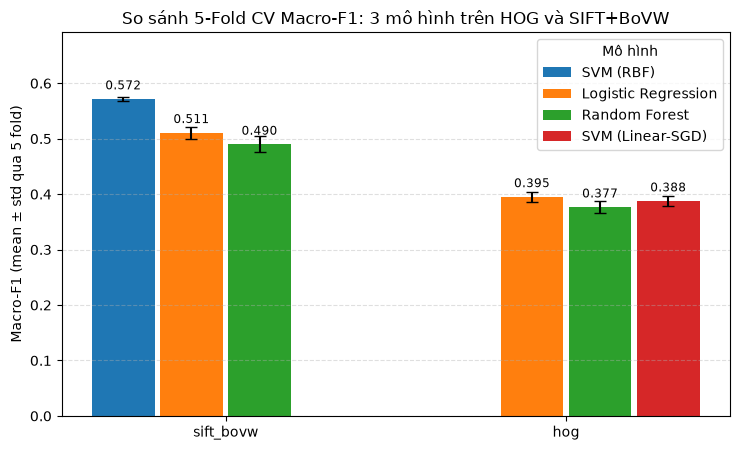

In [5]:
# [5.5.1] Tổng hợp 6 tổ hợp tốt nhất (2 đặc trưng x 3 họ mô hình: LR, SVM, RF)
# Nạp toàn bộ kết quả từ cache để không bị mất khi Restart Kernel
df_baselines = clf.load_cache("baselines", cfg)
df_sift_lr = clf.load_cache("sift_lr", cfg)
df_sift_svm = clf.load_cache("sift_svm", cfg)
df_sift_rf = clf.load_cache("sift_rf", cfg)
df_hog_lr = clf.load_cache("hog_lr", cfg)
df_hog_svm = clf.load_cache("hog_svm", cfg)
df_hog_rf = clf.load_cache("hog_rf", cfg)

df_all_tuning = pd.concat(
    [df_sift_lr, df_sift_svm, df_sift_rf, df_hog_lr, df_hog_svm, df_hog_rf],
    ignore_index=True,
)

# Nhóm LinearSVC, SVM (Linear-SGD) và SVC(RBF) chung vào họ "SVM" để chọn đại diện SVM tốt nhất cho mỗi đặc trưng
df_all_tuning["model_family"] = df_all_tuning["model"].replace({"SVM (Linear)": "SVM", "SVM (Linear-SGD)": "SVM", "SVM (RBF)": "SVM"})
best_6_idx = df_all_tuning.groupby(["feature", "model_family"])["val_f1_mean"].idxmax()
df_best_6 = df_all_tuning.loc[best_6_idx].sort_values("val_f1_mean", ascending=False).reset_index(drop=True)

print("=== Bảng tổng hợp 6 tổ hợp tốt nhất (nhánh Truyền thống) ===")
display(ev.format_results_table(df_best_6))

fig = ev.plot_model_comparison(df_best_6, title="So sánh 5-Fold CV Macro-F1: 3 mô hình trên HOG và SIFT+BoVW")
ev.save_figure(fig, "trad_model_comparison.png", cfg)
plt.show()

Đã lưu biểu đồ: d:\A_Learning\HK1_2026-2027\Program for AI and Data - CO3135\GarbageClassification\artifacts/figures\trad_cm_sift_bovw.png


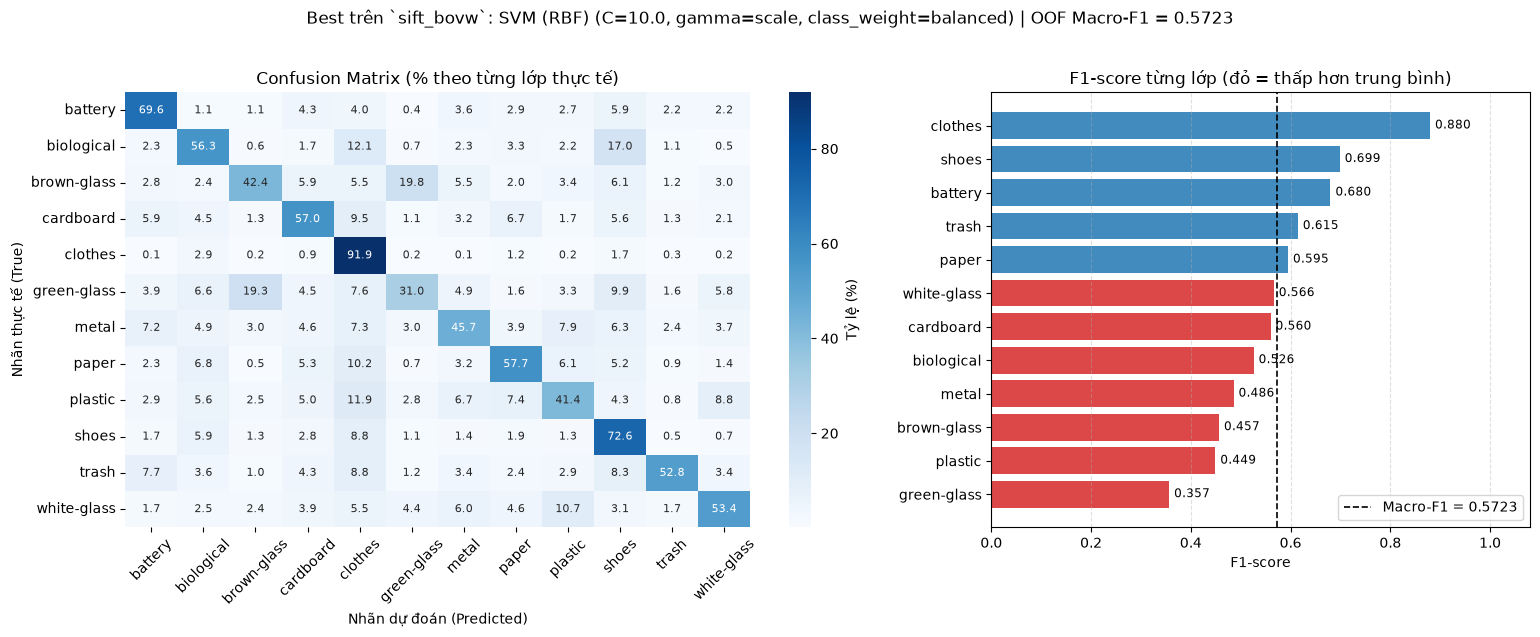

Đã lưu biểu đồ: d:\A_Learning\HK1_2026-2027\Program for AI and Data - CO3135\GarbageClassification\artifacts/figures\trad_cm_hog.png


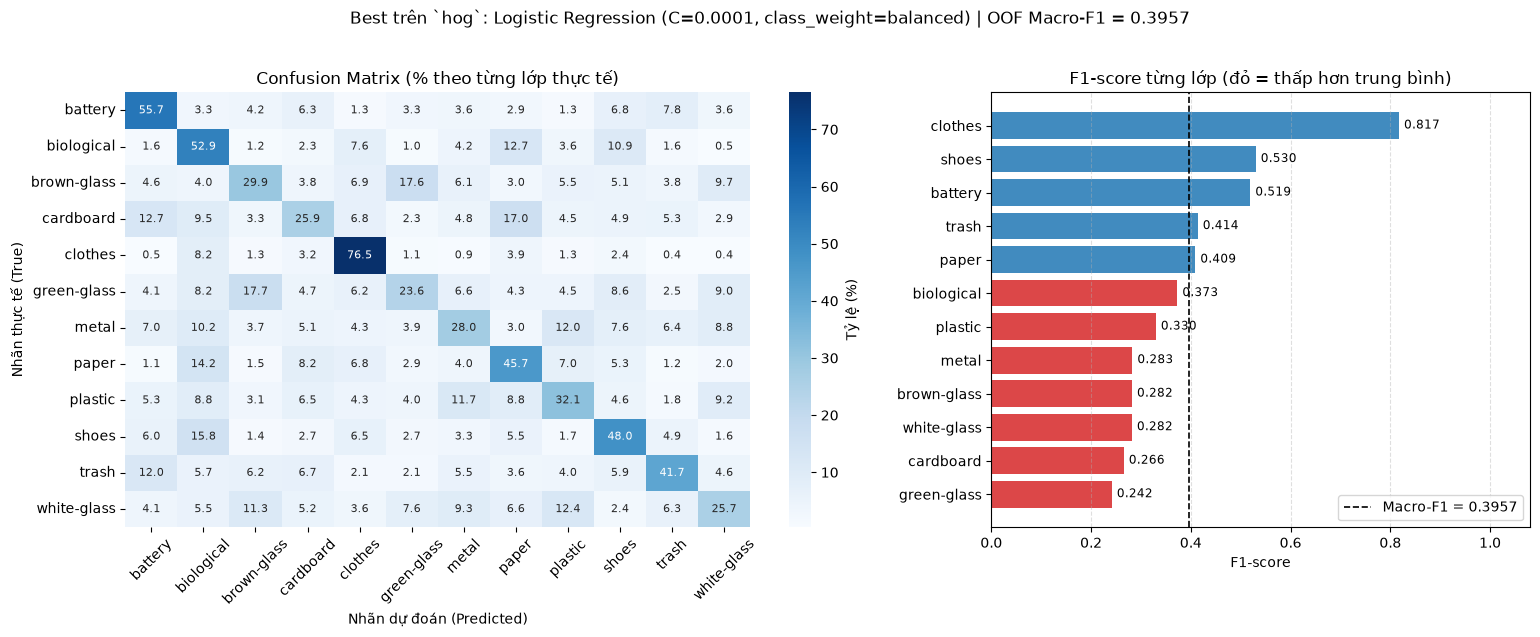

In [6]:
# [5.5.2] Phân tích lỗi (Confusion Matrix & Per-class F1) cho mô hình tốt nhất trên sift_bovw và hog
import json

for feat in ["sift_bovw", "hog"]:
    row_best = df_best_6[df_best_6["feature"] == feat].iloc[0]
    m_type = row_best["model_type"]
    params = json.loads(row_best["params_dict"])
    cv_jobs = 1 if (m_type == "rf" or X_dev[feat].shape[1] > 2000) else -1

    pipe = clf.make_pipeline(m_type, params=params, scale=(m_type != "rf"), seed=SEED)
    y_oof = ev.get_oof_predictions(pipe, X_dev[feat], y_dev, cv, n_jobs=cv_jobs)

    title = f"Best trên `{feat}`: {row_best['model']} ({row_best['params']}) | OOF Macro-F1 = {ev.evaluate_predictions(y_dev, y_oof)['macro_f1']:.4f}"
    fig, rep_df = ev.plot_confusion_matrix_and_f1(y_dev, y_oof, class_names, title=title)
    ev.save_figure(fig, f"trad_cm_{feat}.png", cfg)
    plt.show()

In [7]:
# [5.5.3] Kiểm chứng bổ sung: So sánh HOG (ảnh xám) với HOG + Color Histogram (hog_color)
# Mục đích: kiểm tra xem việc thiếu màu sắc có phải nguyên nhân chính làm 3 lớp thủy tinh bị nhầm lẫn hay không
best_hog_row = df_best_6[df_best_6["feature"] == "hog"].iloc[0]
m_type_h = best_hog_row["model_type"]
params_h = json.loads(best_hog_row["params_dict"])

pipe_hc = clf.make_pipeline(m_type_h, params=params_h, scale=(m_type_h != "rf"), seed=SEED)
res_hc = ev.evaluate_cv(pipe_hc, X_dev["hog_color"], y_dev, cv, "hog_color", best_hog_row["model"], best_hog_row["params"], n_jobs=1)

df_color_cmp = pd.DataFrame([best_hog_row.to_dict(), res_hc])
print("=== Đối chiếu HOG (chỉ hình dạng, ảnh xám) vs HOG + Color (thêm 128 chiều màu HSV) ===")
display(ev.format_results_table(df_color_cmp))

=== Đối chiếu HOG (chỉ hình dạng, ảnh xám) vs HOG + Color (thêm 128 chiều màu HSV) ===


,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,hog_color,Logistic Regression,"C=0.0001, class_weight=balanced",0.5040 ± 0.0073,0.5988 ± 0.0071,0.5016,0.5145,0.7123,5.77
1,hog,Logistic Regression,"C=0.0001, class_weight=balanced",0.3953 ± 0.0094,0.5176 ± 0.0081,0.3964,0.4047,0.6172,92.32


**So sánh 6 tổ hợp.** `sift_bovw + SVM (RBF)` cao nhất (`0.5718 ± 0.0041`). Mọi tổ hợp trên `sift_bovw` đều cao hơn mọi tổ hợp trên `hog`. Độ lệch chuẩn giữa các fold nằm trong khoảng `0.004–0.014`, nhỏ so với khoảng cách giữa hai đặc trưng.

**Phân tích lỗi (dự đoán out-of-fold).**
- Ở cả hai mô hình, ba lớp có F1 cao nhất là `clothes` (`0.880` với `sift_bovw`, `0.817` với `hog`), `shoes` và `battery`. `clothes` chiếm 33% dữ liệu và có kết cấu vải đặc trưng; `shoes` và `battery` có hình dạng ổn định.
- **Ba lớp thủy tinh.** Với `sift_bovw`, `green-glass` có F1 thấp nhất (`0.357`): chỉ `31.0%` ảnh được đoán đúng và `19.3%` bị đoán thành `brown-glass`; ngược lại `19.8%` ảnh `brown-glass` bị đoán thành `green-glass`. Hai lớp này có hình dạng giống nhau và khác nhau chủ yếu ở màu, mà `hog` và `sift_bovw` đều tính trên ảnh xám. `white-glass` lại hay bị nhầm với `plastic` (`10.7%`), có thể vì chai thủy tinh trong và chai nhựa trong trông giống nhau trên ảnh xám.
- **Lỗi đổ về lớp lớn.** Nhiều lớp có 8–12% ảnh bị đoán thành `clothes` (`biological 12.1%`, `plastic 11.9%`, `paper 10.2%` với `sift_bovw`). `biological` còn bị đoán thành `shoes` `17.0%`.
- **Với `hog`, lỗi phân tán hơn.** Không lớp nào ngoài `clothes` có tỷ lệ đúng vượt `56%`. `cardboard` chỉ đúng `25.9%`, bị nhầm sang `paper` (`17.0%`) và `battery` (`12.7%`). Với `sift_bovw`, `cardboard` đúng `57.0%` và nhầm sang `paper` chỉ `6.7%`. Điều này phù hợp với nhận xét ở notebook 03 rằng HOG gắn với lưới cố định nên nhạy khi vật bị dịch hoặc xoay.

**Kiểm chứng vai trò của màu.** Giữ nguyên mô hình tốt nhất trên `hog` (`LR, C=0.0001`) và chỉ thay `hog` bằng `hog_color` (thêm 128 chiều histogram HSV): macro-F1 tăng từ `0.3953` lên `0.5040 ± 0.0073`, accuracy từ `0.5176` lên `0.5988`. Kết quả này ủng hộ giả thuyết rằng thiếu thông tin màu là một nguyên nhân chính khiến đặc trưng ảnh xám bị giới hạn. Lưu ý `C=0.0001` được chọn cho `hog` chứ chưa tuning riêng cho `hog_color`, nên mức `0.5040` có thể chưa phải tối đa.

### 5.6. Ablation: giảm chiều bằng PCA

**Câu hỏi** (theo kế hoạch của nhóm): có thể giảm đặc trưng xuống bao nhiêu chiều mà vẫn giữ được độ chính xác, và giảm chiều giúp chạy nhanh hơn hay làm mất thông tin?

**Ý tưởng của PCA.** Sau khi chuẩn hóa, PCA tìm các hướng (thành phần chính) mà dữ liệu biến thiên nhiều nhất; các hướng này vuông góc với nhau. Chiếu dữ liệu lên $k$ hướng đầu tiên cho một biểu diễn $k$ chiều giữ được nhiều phương sai nhất. Những chiều tương quan mạnh với nhau, ví dụ các ô HOG nằm cạnh nhau, được gộp lại thành ít thành phần hơn.

**Thiết kế thí nghiệm.** PCA được đặt trong `Pipeline`, trước bộ phân loại. Với mỗi đặc trưng, thử nhiều mức $k$ (`hog`: 32–512, `sift_bovw`: 32–256), dùng siêu tham số tốt nhất đã tìm được ở 5.3–5.4, rồi so với kết quả khi không dùng PCA. Riêng SVM RBF trên `hog` chỉ chạy được sau khi đã giảm chiều; mục 5.6.3 tuning thêm `C` cho cấu hình này.

=== Ablation PCA trên `hog` (gốc 8100 chiều) ===
  Logistic Regression  | PCA-32       -> Val F1: 0.3432 ± 0.0139 | Fit: 1.51s/fold (tổng 8.9s)
  Logistic Regression  | PCA-64       -> Val F1: 0.3650 ± 0.0108 | Fit: 1.73s/fold (tổng 9.9s)
  Logistic Regression  | PCA-128      -> Val F1: 0.3754 ± 0.0090 | Fit: 2.68s/fold (tổng 14.8s)
  Logistic Regression  | PCA-256      -> Val F1: 0.3846 ± 0.0079 | Fit: 3.51s/fold (tổng 19.1s)
  Logistic Regression  | PCA-512      -> Val F1: 0.3879 ± 0.0083 | Fit: 6.23s/fold (tổng 33.1s)
  SVM (Linear-SGD)     | PCA-32       -> Val F1: 0.3326 ± 0.0147 | Fit: 1.36s/fold (tổng 8.1s)
  SVM (Linear-SGD)     | PCA-64       -> Val F1: 0.3556 ± 0.0155 | Fit: 1.97s/fold (tổng 11.3s)
  SVM (Linear-SGD)     | PCA-128      -> Val F1: 0.3709 ± 0.0153 | Fit: 2.15s/fold (tổng 12.2s)
  SVM (Linear-SGD)     | PCA-256      -> Val F1: 0.3769 ± 0.0113 | Fit: 21.19s/fold (tổng 113.1s)
  SVM (Linear-SGD)     | PCA-512      -> Val F1: 0.3830 ± 0.0096 | Fit: 78.46s/fold (tổn

,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,hog,Logistic Regression,"C=0.0001, class_weight=balanced",0.3953 ± 0.0094,0.5176 ± 0.0081,0.3964,0.4047,0.6172,92.32
1,hog,SVM (Linear-SGD),"alpha=1.0, class_weight=balanced",0.3877 ± 0.0084,0.5351 ± 0.0093,0.4009,0.3862,0.6227,14.58
2,hog,Random Forest,"n_estimators=200, max_depth=10, max_features=s...",0.3768 ± 0.0102,0.5190 ± 0.0087,0.4308,0.3756,0.9239,65.41
3,hog,Logistic Regression,PCA-32,0.3432 ± 0.0139,0.4692 ± 0.0117,0.3454,0.3545,0.3608,1.51
4,hog,Logistic Regression,PCA-64,0.3650 ± 0.0108,0.4873 ± 0.0100,0.3669,0.3755,0.3930,1.73
5,hog,Logistic Regression,PCA-128,0.3754 ± 0.0090,0.4958 ± 0.0082,0.3767,0.3867,0.4277,2.68
6,hog,Logistic Regression,PCA-256,0.3846 ± 0.0079,0.5076 ± 0.0081,0.3854,0.3954,0.4583,3.51
7,hog,Logistic Regression,PCA-512,0.3879 ± 0.0083,0.5107 ± 0.0075,0.3889,0.3983,0.4993,6.23
8,hog,SVM (Linear-SGD),PCA-32,0.3326 ± 0.0147,0.4869 ± 0.0168,0.3555,0.3313,0.3483,1.36
9,hog,SVM (Linear-SGD),PCA-64,0.3556 ± 0.0155,0.5095 ± 0.0150,0.3765,0.3524,0.3893,1.97


Đã lưu biểu đồ: d:\A_Learning\HK1_2026-2027\Program for AI and Data - CO3135\GarbageClassification\artifacts/figures\trad_ablation_pca_hog.png


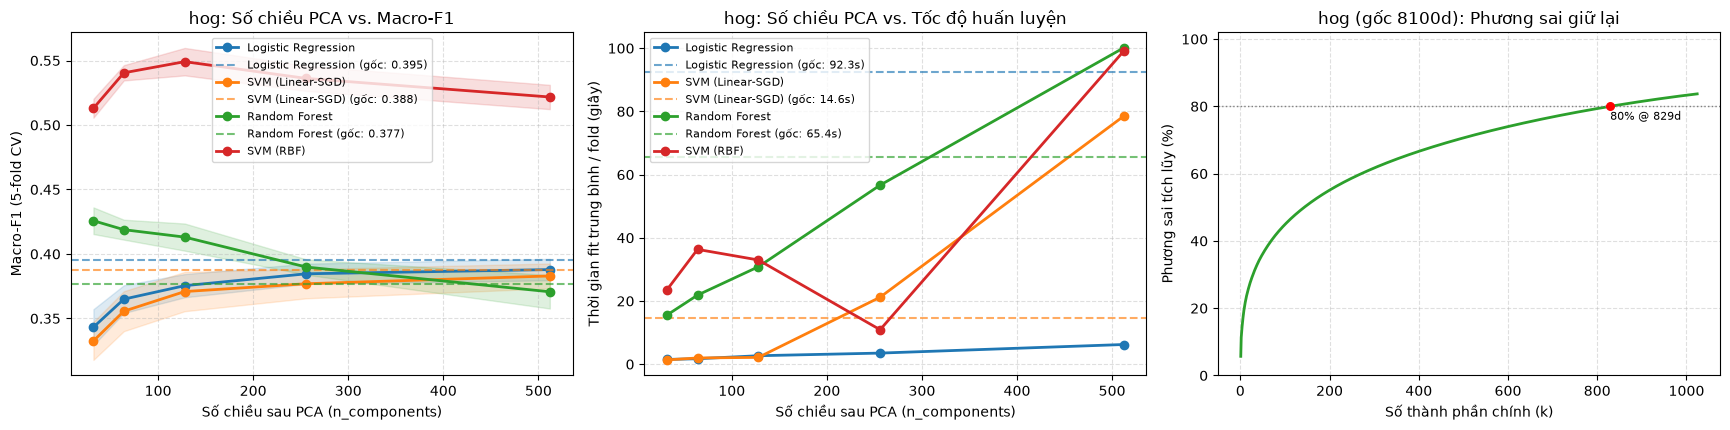

In [8]:
# [5.6.1] Ablation PCA trên `hog` (gốc 8100 chiều)
best_hog_lr = clf.best_from_df(clf.load_cache("hog_lr", cfg))
best_hog_svm = clf.best_from_df(clf.load_cache("hog_svm", cfg))
best_hog_rf = clf.best_from_df(clf.load_cache("hog_rf", cfg))

cum_var_hog = clf.compute_pca_variance(X_dev["hog"], max_components=1024, seed=SEED)

hog_pca_specs = [
    {"model_type": "lr", "params": best_hog_lr["params"], "label": "Logistic Regression"},
    {"model_type": "sgd_svm", "params": best_hog_svm["params"], "label": "SVM (Linear-SGD)"},
    {"model_type": "rf", "params": best_hog_rf["params"], "label": "Random Forest"},
    {"model_type": "rbf_svm", "params": {"C": 5.0, "class_weight": "balanced"}, "label": "SVM (RBF)"},
]
df_pca_hog = clf.run_pca_ablation(
    "hog", X_dev["hog"], y_dev, cv,
    model_specs=hog_pca_specs,
    k_list=[32, 64, 128, 256, 512],
    seed=SEED,
    include_original=False,
)

# Ghép lại kết quả gốc (8100d) đã chạy ở mục 5.4 để vẽ đường so sánh mà không phải chạy lại
orig_hog = df_best_6[df_best_6["feature"] == "hog"].copy()
orig_hog["pca_dims"] = np.nan
df_pca_hog = pd.concat([orig_hog, df_pca_hog], ignore_index=True)
clf.save_cache(df_pca_hog, "pca_hog", cfg)

display(ev.format_results_table(df_pca_hog, sort_by=None))
fig = ev.plot_pca_ablation(df_pca_hog, "hog", cum_var=cum_var_hog, orig_dims=X_dev["hog"].shape[1])
ev.save_figure(fig, "trad_ablation_pca_hog.png", cfg)
plt.show()

=== Ablation PCA trên `sift_bovw` (gốc 500 chiều) ===
  Logistic Regression  | PCA-32       -> Val F1: 0.4025 ± 0.0028 | Fit: 0.43s/fold (tổng 6.0s)
  Logistic Regression  | PCA-64       -> Val F1: 0.4471 ± 0.0064 | Fit: 1.97s/fold (tổng 11.2s)
  Logistic Regression  | PCA-128      -> Val F1: 0.4760 ± 0.0072 | Fit: 3.73s/fold (tổng 20.5s)
  Logistic Regression  | PCA-256      -> Val F1: 0.4967 ± 0.0103 | Fit: 5.40s/fold (tổng 23.5s)
  SVM (RBF)            | PCA-32       -> Val F1: 0.5220 ± 0.0075 | Fit: 20.07s/fold (tổng 56.3s)
  SVM (RBF)            | PCA-64       -> Val F1: 0.5517 ± 0.0050 | Fit: 28.55s/fold (tổng 83.4s)
  SVM (RBF)            | PCA-128      -> Val F1: 0.5706 ± 0.0041 | Fit: 72.49s/fold (tổng 238.3s)
  SVM (RBF)            | PCA-256      -> Val F1: 0.5744 ± 0.0055 | Fit: 175.51s/fold (tổng 375.1s)
  Random Forest        | PCA-32       -> Val F1: 0.4989 ± 0.0034 | Fit: 2.08s/fold (tổng 11.3s)
  Random Forest        | PCA-64       -> Val F1: 0.5026 ± 0.0026 | Fit: 1.61

,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,sift_bovw,SVM (RBF),"C=10.0, gamma=scale, class_weight=balanced",0.5718 ± 0.0041,0.6791 ± 0.0037,0.5920,0.5599,0.9939,208.33
1,sift_bovw,Logistic Regression,"C=0.002, class_weight=balanced",0.5110 ± 0.0109,0.6079 ± 0.0042,0.5065,0.5241,0.6122,0.99
2,sift_bovw,Random Forest,"n_estimators=200, max_depth=15, max_features=s...",0.4899 ± 0.0142,0.5947 ± 0.0102,0.5401,0.4707,0.9636,0.84
3,sift_bovw,Logistic Regression,PCA-32,0.4025 ± 0.0028,0.5013 ± 0.0044,0.4022,0.4164,0.4174,0.43
4,sift_bovw,Logistic Regression,PCA-64,0.4471 ± 0.0064,0.5455 ± 0.0046,0.4455,0.4615,0.4698,1.97
5,sift_bovw,Logistic Regression,PCA-128,0.4760 ± 0.0072,0.5752 ± 0.0053,0.4724,0.4901,0.5202,3.73
6,sift_bovw,Logistic Regression,PCA-256,0.4967 ± 0.0103,0.5957 ± 0.0056,0.4924,0.5104,0.5683,5.40
7,sift_bovw,SVM (RBF),PCA-32,0.5220 ± 0.0075,0.6231 ± 0.0059,0.5245,0.5291,0.8849,20.07
8,sift_bovw,SVM (RBF),PCA-64,0.5517 ± 0.0050,0.6532 ± 0.0041,0.5570,0.5533,0.9501,28.55
9,sift_bovw,SVM (RBF),PCA-128,0.5706 ± 0.0041,0.6744 ± 0.0039,0.5805,0.5667,0.9777,72.49


Đã lưu biểu đồ: d:\A_Learning\HK1_2026-2027\Program for AI and Data - CO3135\GarbageClassification\artifacts/figures\trad_ablation_pca_sift.png


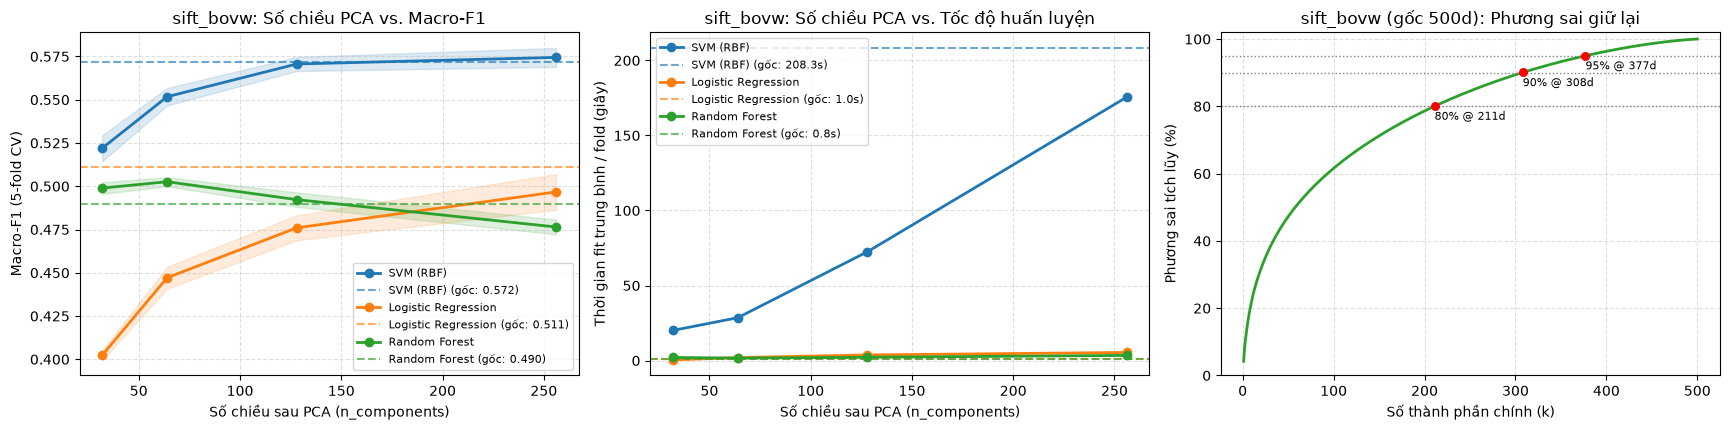

In [9]:
# [5.6.2] Ablation PCA trên `sift_bovw` (gốc 500 chiều)
best_sift_lr = clf.best_from_df(clf.load_cache("sift_lr", cfg))
df_sift_svm_c = clf.load_cache("sift_svm", cfg)
best_sift_rbf = clf.best_from_df(df_sift_svm_c[df_sift_svm_c["model_type"] == "rbf_svm"])
best_sift_rf = clf.best_from_df(clf.load_cache("sift_rf", cfg))

cum_var_sift = clf.compute_pca_variance(X_dev["sift_bovw"], max_components=500, seed=SEED)

sift_pca_specs = [
    {"model_type": "lr", "params": best_sift_lr["params"], "label": "Logistic Regression"},
    {"model_type": "rbf_svm", "params": best_sift_rbf["params"], "label": "SVM (RBF)"},
    {"model_type": "rf", "params": best_sift_rf["params"], "label": "Random Forest"},
]
df_pca_sift = clf.run_pca_ablation(
    "sift_bovw", X_dev["sift_bovw"], y_dev, cv,
    model_specs=sift_pca_specs,
    k_list=[32, 64, 128, 256],
    seed=SEED,
    include_original=False,
)

# Ghép lại kết quả gốc (500d) đã chạy ở mục 5.3 để không phải chạy lại SVM RBF
orig_sift = df_best_6[df_best_6["feature"] == "sift_bovw"].copy()
orig_sift["pca_dims"] = np.nan
df_pca_sift = pd.concat([orig_sift, df_pca_sift], ignore_index=True)
clf.save_cache(df_pca_sift, "pca_sift", cfg)

display(ev.format_results_table(df_pca_sift, sort_by=None))
fig = ev.plot_pca_ablation(df_pca_sift, "sift_bovw", cum_var=cum_var_sift, orig_dims=X_dev["sift_bovw"].shape[1])
ev.save_figure(fig, "trad_ablation_pca_sift.png", cfg)
plt.show()

**Phương sai giữ lại.** Trên `hog` (8 100 chiều), cần tới `829` thành phần chính mới giữ được `80%` phương sai, cho thấy năng lượng của gradient phân tán trên rất nhiều chiều. Trên `sift_bovw` (500 chiều), `211` chiều giữ `80%`, `308` chiều giữ `90%` và `377` chiều giữ `95%` phương sai.

**Kết quả trên `hog` (gốc 8 100 chiều).**
- **SVM RBF** chỉ chạy được sau PCA. Với `k = 32, 64, 128, 256, 512`, val F1 lần lượt là `0.5130`, `0.5405`, `0.5491 ± 0.0106`, `0.5361`, `0.5217`; đỉnh tại `k=128`. So với mức tốt nhất trên `hog` gốc (`0.3953`), đây là mức tăng khoảng 0.15, đưa `hog` lên gần `sift_bovw`. Mức tăng này đến từ việc PCA cho phép dùng kernel phi tuyến, chứ không đến từ bản thân việc giảm chiều. Ở đây `C=5` được cố định; mục 5.6.3 tuning lại `C` tại `k=128`.
- **Random Forest** cải thiện khi giảm chiều mạnh: `k=32` đạt `0.4258 ± 0.0103` (gốc `0.3768`), và điểm giảm dần khi `k` tăng. Mỗi lần chia nút trên 8 100 chiều gốc chỉ xét ngẫu nhiên khoảng 90 chiều, phần lớn là chiều ít thông tin; các thành phần chính tập trung thông tin hơn.
- **Logistic Regression và Linear SVM (SGD)** không cải thiện: tốt nhất ở `k=512` (`0.3879` và `0.3830`), thấp hơn một chút so với gốc (`0.3953`, `0.3877`). Đổi lại, thời gian fit của Logistic Regression giảm từ `92.3 s` xuống `6.2 s`/fold.

**Kết quả trên `sift_bovw` (gốc 500 chiều).**
- **SVM RBF:** `k=128` đạt `0.5706 ± 0.0041` với thời gian fit `72.5 s`/fold; `k=256` đạt `0.5744 ± 0.0055`. Cả hai mức chênh so với gốc (`0.5718`) đều nhỏ hơn độ lệch chuẩn giữa các fold, nên coi là **tương đương** gốc chứ không phải tốt hơn.
- **Logistic Regression** giảm theo số chiều giữ lại (`k=256`: `0.4967`, gốc `0.5110`), tức PCA làm mất một phần thông tin hữu ích với mô hình tuyến tính.
- **Random Forest** tốt nhất ở `k=64` (`0.5026 ± 0.0026`, gốc `0.4899`).

**Trả lời câu hỏi ablation.**
- *Nén xuống bao nhiêu chiều mà vẫn giữ độ chính xác?* Với SVM RBF, khoảng `128` chiều là đủ trên cả hai đặc trưng (`hog`: 8 100 → 128; `sift_bovw`: 500 → 128 mà giữ nguyên macro-F1). Với Logistic Regression, PCA luôn làm giảm nhẹ macro-F1 trong các mức đã thử.
- *Giảm chiều giúp nhanh hơn hay làm mất thông tin?* Phụ thuộc mô hình. PCA giảm mạnh thời gian huấn luyện và có lợi cho Random Forest và SVM RBF. Với mô hình tuyến tính, PCA làm mất một ít thông tin.
- Thời gian fit chỉ dùng để so sánh tương đối: các lần chạy dùng số tiến trình song song khác nhau (`n_jobs=1` cho `hog`, `n_jobs=-1` cho `sift_bovw`).

**5.6.3. Tuning `C` cho SVM RBF trên `hog` + PCA-128.** Ở 5.6.1, SVM RBF trên `hog` dùng `C=5` cố định, chưa tuning như các mô hình khác. Ô dưới cố định `k=128` (mức tốt nhất ở 5.6.1) và thử `C ∈ {1, 5, 10, 20}`, để so sánh với `sift_bovw` công bằng hơn.

=== Tuning SVM (RBF) trên `hog` (4 cấu hình × 5 fold) ===
  [1/4] pca=128, C=1.0, gamma=scale, class_weight=balanced -> Val F1: 0.5298 ± 0.0075 | Train F1: 0.8712 | (185.5s)
  [2/4] pca=128, C=5.0, gamma=scale, class_weight=balanced -> Val F1: 0.5491 ± 0.0106 | Train F1: 0.9845 | (412.6s)
  [3/4] pca=128, C=10.0, gamma=scale, class_weight=balanced -> Val F1: 0.5499 ± 0.0096 | Train F1: 0.9953 | (328.0s)
  [4/4] pca=128, C=20.0, gamma=scale, class_weight=balanced -> Val F1: 0.5479 ± 0.0088 | Train F1: 0.9988 | (516.7s)
--> Tốt nhất: pca=128, C=10.0, gamma=scale, class_weight=balanced | Macro-F1 = 0.5499 ± 0.0096



,Đặc trưng,Mô hình,Tham số,Macro-F1 (Val),Accuracy (Val),Macro-Prec,Macro-Rec,Train F1,Fit (s/fold)
0,hog,SVM (RBF),"pca=128, C=10.0, gamma=scale, class_weight=bal...",0.5499 ± 0.0096,0.6748 ± 0.0079,0.5654,0.5444,0.9953,29.88
1,hog,SVM (RBF),"pca=128, C=5.0, gamma=scale, class_weight=bala...",0.5491 ± 0.0106,0.6716 ± 0.0081,0.5632,0.5463,0.9845,38.46
2,hog,SVM (RBF),"pca=128, C=20.0, gamma=scale, class_weight=bal...",0.5479 ± 0.0088,0.6742 ± 0.0068,0.5644,0.5408,0.9988,46.68
3,hog,SVM (RBF),"pca=128, C=1.0, gamma=scale, class_weight=bala...",0.5298 ± 0.0075,0.6381 ± 0.0067,0.5414,0.5355,0.8712,14.20


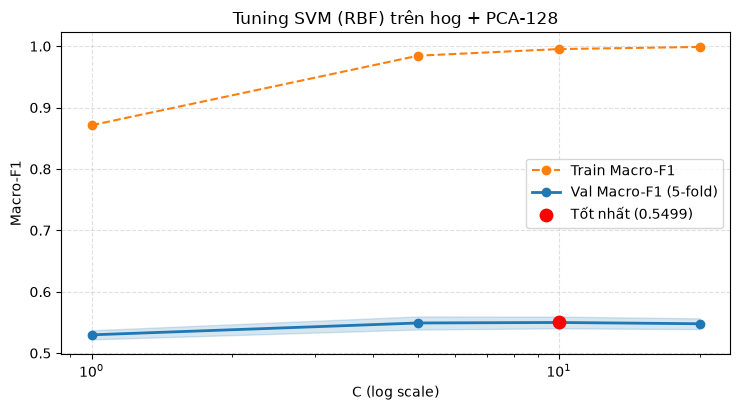

In [2]:
# [5.6.3] Tuning C cho SVM (RBF) trên hog sau PCA-128
hog_rbf_grid = [{"C": c, "gamma": "scale", "class_weight": "balanced"} for c in [1.0, 5.0, 10.0, 20.0]]
df_hog_rbf_pca, best_hog_rbf_pca = clf.tune_model(
    "hog", X_dev["hog"], y_dev, cv, "rbf_svm", hog_rbf_grid, pca_dims=128, seed=SEED,
)
clf.save_cache(df_hog_rbf_pca, "hog_rbf_pca128", cfg)
display(ev.format_results_table(df_hog_rbf_pca))

fig = ev.plot_tuning_curve(df_hog_rbf_pca, "param_C", "Tuning SVM (RBF) trên hog + PCA-128", x_label="C (log scale)", log_x=True)
plt.show()

**Kết quả 5.6.3.** Tại `k=128`, `C=10` đạt `0.5499 ± 0.0096` (accuracy `0.6748`), chỉ nhỉnh hơn `C=5` (`0.5491 ± 0.0106`) trong phạm vi sai số và giảm nhẹ về `0.5479` ở `C=20`. Ngay cả sau khi tuning `C`, `hog + PCA-128 + SVM RBF` vẫn thấp hơn `sift_bovw + SVM RBF` khoảng `0.022`.

### 5.7. Lưu kết quả

Lưu các bảng kết quả và cấu hình tốt nhất vào `artifacts/results/` để notebook 07 sử dụng. Ô này chỉ đọc từ cache, nên có thể chạy riêng sau `[5.1]`.

In [3]:
# [5.7] Lưu bảng kết quả (.csv) và cấu hình tốt nhất (.json), đọc toàn bộ từ cache
import json, os
names = ["sift_lr", "sift_svm", "sift_rf", "hog_lr", "hog_svm", "hog_rf"]
df_baselines = clf.load_cache("baselines", cfg)
df_all_tuning = pd.concat([clf.load_cache(n, cfg) for n in names], ignore_index=True)
df_all_tuning["model_family"] = df_all_tuning["model"].replace(
    {"SVM (Linear)": "SVM", "SVM (Linear-SGD)": "SVM", "SVM (RBF)": "SVM"})
df_best_6 = (df_all_tuning.loc[df_all_tuning.groupby(["feature", "model_family"])["val_f1_mean"].idxmax()]
             .sort_values("val_f1_mean", ascending=False).reset_index(drop=True))

pca_parts = [clf.load_cache("pca_hog", cfg), clf.load_cache("pca_sift", cfg)]
if os.path.exists(os.path.join(cfg["results_dir"], "cache", "hog_rbf_pca128.csv")):
    extra = clf.load_cache("hog_rbf_pca128", cfg)
    extra["pca_dims"] = 128
    pca_parts.append(extra)
df_pca_all = pd.concat(pca_parts, ignore_index=True)
df_pca_all = df_pca_all[df_pca_all["pca_dims"].notna()].reset_index(drop=True)   # bỏ các dòng gốc đã có trong df_best_6

ev.save_results(df_baselines, "trad_baselines_cv.csv", cfg)
ev.save_results(df_all_tuning, "trad_tuning_cv.csv", cfg)
ev.save_results(df_best_6, "trad_best_models_cv.csv", cfg)
ev.save_results(df_pca_all, "trad_ablation_pca_cv.csv", cfg)

cols = ["feature", "model", "params", "val_f1_mean", "val_f1_std", "val_acc_mean", "fit_time_mean"]
df_candidates = (pd.concat([df_best_6[cols], df_pca_all[cols]], ignore_index=True)
                 .drop_duplicates(subset=["feature", "model", "params"])
                 .sort_values("val_f1_mean", ascending=False).reset_index(drop=True))
best = df_candidates.iloc[0].to_dict()
ev.save_json(best, "trad_best_config_cv.json", cfg)

print("5 cấu hình có macro-F1 cao nhất (5-fold CV):")
display(df_candidates.head(5))

Đã lưu bảng kết quả: d:\A_Learning\HK1_2026-2027\Program for AI and Data - CO3135\GarbageClassification\artifacts/results\trad_baselines_cv.csv (4 dòng)
Đã lưu bảng kết quả: d:\A_Learning\HK1_2026-2027\Program for AI and Data - CO3135\GarbageClassification\artifacts/results\trad_tuning_cv.csv (48 dòng)
Đã lưu bảng kết quả: d:\A_Learning\HK1_2026-2027\Program for AI and Data - CO3135\GarbageClassification\artifacts/results\trad_best_models_cv.csv (6 dòng)
Đã lưu bảng kết quả: d:\A_Learning\HK1_2026-2027\Program for AI and Data - CO3135\GarbageClassification\artifacts/results\trad_ablation_pca_cv.csv (36 dòng)
Đã lưu JSON: d:\A_Learning\HK1_2026-2027\Program for AI and Data - CO3135\GarbageClassification\artifacts/results\trad_best_config_cv.json
5 cấu hình có macro-F1 cao nhất (5-fold CV):


,feature,model,params,val_f1_mean,val_f1_std,val_acc_mean,fit_time_mean
0,sift_bovw,SVM (RBF),PCA-256,0.574442,0.005479,0.681216,175.513437
1,sift_bovw,SVM (RBF),"C=10.0, gamma=scale, class_weight=balanced",0.571800,0.004100,0.679100,208.330000
2,sift_bovw,SVM (RBF),PCA-128,0.570637,0.004073,0.674362,72.489036
3,sift_bovw,SVM (RBF),PCA-64,0.551720,0.005029,0.653246,28.551599
4,hog,SVM (RBF),"pca=128, C=10.0, gamma=scale, class_weight=bal...",0.549940,0.009575,0.674835,29.884944


### 5.8. Tổng kết

| Đặc trưng | Cấu hình tốt nhất | Macro-F1 (5-fold) | Accuracy |
|---|---|---|---|
| `sift_bovw` | PCA-256 + SVM RBF (`C=10`) | `0.5744 ± 0.0055` | `0.6812` |
| `sift_bovw` | SVM RBF (`C=10`), không PCA | `0.5718 ± 0.0041` | `0.6791` |
| `hog` | PCA-128 + SVM RBF (`C=10`) | `0.5499 ± 0.0096` | `0.6748` |
| `hog` | Logistic Regression (`C=0.0001`), không PCA | `0.3953 ± 0.0094` | `0.5176` |

- **Cấu hình tốt nhất của nhánh truyền thống** là `sift_bovw` + SVM RBF. Biến thể có PCA-256, không PCA và PCA-128 (`0.5706`) chênh nhau trong phạm vi độ lệch chuẩn, nên có thể xem là tương đương. File `trad_best_config_cv.json` ghi biến thể có trung bình cao nhất (PCA-256).
- So với baseline sàn (`0.0793`) và baseline chính (LR mặc định trên `sift_bovw`, `0.4600`), cấu hình tốt nhất cao hơn lần lượt khoảng 0.50 và 0.11.
- Các giới hạn chính của đặc trưng truyền thống thấy được qua thực nghiệm: không có màu (3 lớp thủy tinh), HOG nhạy với vị trí vật, và xu hướng đoán nhầm về lớp `clothes`.

**Lưu ý khi đọc kết quả.**
- Siêu tham số được chọn trên chính 5 fold dùng để báo cáo điểm, nên các con số trên có thể hơi lạc quan. Đánh giá khách quan sẽ thực hiện trên tập final test ở `07_final_evaluation.ipynb`.
